In [1]:
import os

os.environ["R_HOME"] = "/Library/Frameworks/R.framework/Resources"

In [2]:
import scanpy as sc
import logging
import rpy2.rinterface_lib.callbacks as rcb

sc.settings.verbosity = 0
rcb.logger.setLevel(logging.ERROR)

Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/modeller/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/gernotstuhler/miniforge3_arm64/envs/modeller/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In [3]:
%load_ext rpy2.ipython

In [4]:
%%R
# ============================================
# SETUP — Pakete + Namespace-Konflikte einmalig lösen
# ============================================
library(readr)
library(readxl)
library(dplyr)
library(tidyr)
library(tibble)
library(ggplot2)
library(ggpubr)      # für stat_cor() -> R/p-Wert im Panel
library(patchwork)   # für die finale 3x3-Kombination
library(org.Hs.eg.db)
library(AnnotationDbi)

# AnnotationDbi maskiert dplyr::select/rename/filter -> einmalig fixieren
select <- dplyr::select
rename <- dplyr::rename
filter <- dplyr::filter

dir.create("output", showWarnings = FALSE)


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

Loading required package: AnnotationDbi
Loading required package: stats4
Loading required package: BiocGenerics
Loading required package: generics

Attaching package: ‘generics’

The following object is masked from ‘package:dplyr’:

    explain

The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union


Attaching package: ‘BiocGenerics’

The following object is masked from ‘package:dplyr’:

    combine

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.un

In [5]:
%%R
# ============================================
# Hallmark EMT Gene-Set aus MSigDB-TSV-Format einlesen
# ============================================

emt_geneset_path <- "data/HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION.v2026.1.Hs.tsv"

emt_raw <- read_delim(
    emt_geneset_path,
    delim = "\t",
    col_names = c("field", "value"),
    show_col_types = FALSE
)

cat("Eingelesene Felder:\n")
print(emt_raw$field)

# GENE_SYMBOLS-Zeile extrahieren (aktuelle, kuratierte Symbolliste,
# nicht SOURCE_MEMBERS - das enthält Legacy/alternative Namen)
emt_genes_row <- emt_raw %>% filter(field == "GENE_SYMBOLS") %>% pull(value)

emt_genes_symbol <- strsplit(emt_genes_row, ",")[[1]]

cat("\nAnzahl Gene im Hallmark EMT Set:", length(emt_genes_symbol), "\n")
cat("Beispiele:", paste(head(emt_genes_symbol, 5), collapse = ", "), "\n")

Eingelesene Felder:
 [1] "STANDARD_NAME"                    "SYSTEMATIC_NAME"                 
 [3] "COLLECTION"                       "MSIGDB_URL"                      
 [5] "NAMESPACE"                        "DESCRIPTION_BRIEF"               
 [7] "DESCRIPTION_FULL"                 "PMID"                            
 [9] "GEOID"                            "AUTHORS"                         
[11] "CONTRIBUTOR"                      "CONTRIBUTOR_ORG"                 
[13] "EXACT_SOURCE"                     "FILTERED_BY_SIMILARITY"          
[15] "EXTERNAL_NAMES_FOR_SIMILAR_TERMS" "EXTERNAL_DETAILS_URL"            
[17] "SOURCE_MEMBERS"                   "GENE_SYMBOLS"                    
[19] "FOUNDER_NAMES"                   

Anzahl Gene im Hallmark EMT Set: 200 
Beispiele: ABI3BP, ACTA2, ADAM12, ANPEP, APLP1 


In [6]:
%%R
# ============================================
# BCSC-associated protein composite (direkt via Gene-Symbol)
# ============================================

bcsc_genes_symbol <- c("CD44", "ALDH1A1", "ALDH1A3", "ITGA6", "PROM1")

In [7]:
%%R
# ============================================
# HELPER-FUNKTIONEN (einmalig, statt mehrfach dupliziert)
# ============================================

# Kohort-Z-Score
z <- function(x) as.numeric(scale(x, center = TRUE, scale = TRUE))

# Programme-Score: mittlerer Z-Score über verfügbare Proteine eines Gene-Sets
programme_score <- function(protein_matrix, genes) {
    genes_used <- intersect(genes, rownames(protein_matrix))
m <- protein_matrix[genes_used, , drop = FALSE]
mz <- t(scale(t(m), center = TRUE, scale = TRUE))
score <- colMeans(mz, na.rm = TRUE)
data.frame(
    sample_id = colnames(protein_matrix),
    score = score,
    n_features = colSums(!is.na(mz))
)
}

# Kanonische UniProt-ID ohne Isoform-Suffix (z.B. "P16070-16" -> "P16070")
canonical_uniprot <- function(x) sub("-[0-9]+$", "", x)


In [8]:
%%R
make_scatter <- function(df, xvar, yvar, xlab, ylab, title, color_var = NULL, legend_title = "Subtype", show_stats = TRUE) {
    p <- ggplot(df, aes(x = .data[[xvar]], y = .data[[yvar]]))
if (!is.null(color_var)) {
p <- p + aes(color = .data[[color_var]]) + geom_point(size = 1.8, alpha = 0.8)
} else {
p <- p + geom_point(size = 1.8, alpha = 0.8, color = "steelblue")
}
p <- p +
geom_hline(yintercept = 0, linetype = "dashed", color = "grey60", linewidth = 0.3) +
geom_vline(xintercept = 0, linetype = "dashed", color = "grey60", linewidth = 0.3)


if (show_stats) {
    p <- p +
        ggpubr::stat_cor(
            aes(label = sprintf("rho == %.6f", after_stat(r))),
            method = "spearman", parse = TRUE,
            label.x.npc = 0.65, label.y.npc = 0.12,
            size = 16/.pt, color = "black"
        ) +
        ggpubr::stat_cor(
            aes(label = sprintf("italic(P) == %.6f", after_stat(p))),
            method = "spearman", parse = TRUE,
            label.x.npc = 0.65, label.y.npc = 0.04,
            size = 16/.pt, color = "black"
        )
}

p +
labs(title = title, x = xlab, y = ylab,
color = if (!is.null(color_var)) legend_title else NULL) +
theme_minimal(base_size = 16) +
theme(
    plot.title = element_text(face = "bold", size = 16),
    axis.title = element_text(size = 16),
    axis.text  = element_text(size = 16),   # <- add this
    plot.margin = margin(4, 4, 4, 4),
    legend.key.size = unit(0.8, "lines"),
    legend.text = element_text(size = 16),
    legend.title = element_text(size = 16)
)
}

In [9]:
%%R
# ============================================
# DATASET 1: Einlesen + ROR1/EGFR + Lehmann-Subtyp
# ============================================

df1 <- read_delim("data/LEE_MOESM2_ESM.csv", delim = ";", skip = 1,
                  locale = locale(decimal_mark = ","), show_col_types = FALSE)

target_ids <- c(ROR1 = "Q01973", EGFR = "P00533")
df1_targets <- df1 %>% filter(ProteinID %in% target_ids)

df1_wide <- df1_targets %>%
select(-`Reference Intensity`) %>%
pivot_longer(-ProteinID, names_to = "SampleID", values_to = "Expression") %>%
pivot_wider(names_from = ProteinID, values_from = Expression) %>%
rename(ROR1 = Q01973, EGFR = P00533)

subtype1_raw <- read_delim("data/lehmann.csv", delim = ";", show_col_types = FALSE)
colnames(subtype1_raw)[1] <- "SampleID"
df1_subtype <- subtype1_raw %>%
pivot_longer(-SampleID, names_to = "Subtype", values_to = "flag") %>%
filter(flag == "TRUE") %>%
select(SampleID, Subtype)

df1_final <- df1_wide %>%
left_join(df1_subtype, by = "SampleID") %>%
mutate(
    ROR1_z = z(ROR1),
    EGFR_z = z(EGFR),
    pair_mean_z = (ROR1_z + EGFR_z) / 2,
    pair_AND_z  = pmin(ROR1_z, EGFR_z)
)

cat("Dataset 1 — Samples:", nrow(df1_final), "\n")
print(table(df1_final$Subtype, useNA = "ifany"))

New names:
• `` -> `...1`
Dataset 1 — Samples: 50 

             Basal-like 1              Basal-like 2          Immunomodulatory 
                        4                         4                        16 
Luminal androgen receptor               Mesenchymal     Mesenchymal stem-like 
                        2                        11                         3 
           Not available                Unspecified 
                        8                         2 


In [10]:
%%R
# ============================================
# DATASET 1: EMT- und BCSC-Score (isoform-aware UniProt-Mapping)
# ============================================

emt_map <- AnnotationDbi::select(org.Hs.eg.db, keys = emt_genes_symbol,
                                 keytype = "SYMBOL", columns = "UNIPROT") %>%
mutate(UniProt_canonical = canonical_uniprot(UNIPROT))
emt_uniprot_ids <- unique(na.omit(emt_map$UniProt_canonical))

protein_id_map1 <- df1 %>%
select(ProteinID) %>%
mutate(ProteinID_clean = gsub('"', '', ProteinID)) %>%
separate_rows(ProteinID_clean, sep = ";") %>%
mutate(UniProt_canonical = canonical_uniprot(ProteinID_clean)) %>%
distinct()

protein_matrix1 <- df1 %>%
select(-`Reference Intensity`) %>%
column_to_rownames("ProteinID") %>%
as.matrix()

# EMT: Isoformen pro kanonischem Protein mitteln
emt_protein_map1 <- protein_id_map1 %>% filter(UniProt_canonical %in% emt_uniprot_ids)
emt_matrix1 <- protein_matrix1[intersect(emt_protein_map1$ProteinID_clean, rownames(protein_matrix1)), , drop = FALSE]
rn_map1 <- emt_protein_map1 %>% filter(ProteinID_clean %in% rownames(emt_matrix1)) %>%
select(ProteinID_clean, UniProt_canonical)
emt_matrix1_canon <- rowsum(emt_matrix1, group = rn_map1$UniProt_canonical, reorder = FALSE)
iso_counts1 <- table(rn_map1$UniProt_canonical)
emt_matrix1_canon <- emt_matrix1_canon / as.numeric(iso_counts1[rownames(emt_matrix1_canon)])

emt_scores1 <- programme_score(emt_matrix1_canon, rownames(emt_matrix1_canon))

# BCSC: kanonische UniProt-IDs explizit
bcsc_uniprot_map <- c(
    CD44 = "P16070-16", ALDH1A1 = "P00352", ALDH1A3 = "P47895",
    ITGA6 = "P23229-3;P23229-7", PROM1 = "O43490-2"
)
bcsc_ids1 <- unname(bcsc_uniprot_map[bcsc_uniprot_map %in% rownames(protein_matrix1)])
bcsc_scores1 <- programme_score(protein_matrix1, bcsc_ids1)

df1_final <- df1_final %>%
left_join(rename(emt_scores1, SampleID = sample_id, EMT_score = score, EMT_n_features = n_features), by = "SampleID") %>%
left_join(rename(bcsc_scores1, SampleID = sample_id, BCSC_score = score, BCSC_n_features = n_features), by = "SampleID")

'select()' returned 1:many mapping between keys and columns


In [11]:
%%R
# ============================================
# DATASET 1: die drei Panels
# ============================================

p11 <- make_scatter(df1_final, "EGFR_z", "ROR1_z", "EGFR (z-Score)", "ROR1 (z-Score)",
                    "", color_var = "Subtype")
p12 <- make_scatter(df1_final, "pair_mean_z", "EMT_score", "ROR1-EGFR Pair Score", "EMT Score",
                    "", color_var = "Subtype")
p13 <- make_scatter(df1_final, "pair_mean_z", "BCSC_score", "ROR1-EGFR Pair Score", "BCSC Score",
                    "", color_var = "Subtype")

In addition: Warning messages:
1: Duplicated aesthetics after name standardisation: parse 
2: Duplicated aesthetics after name standardisation: parse 
3: Duplicated aesthetics after name standardisation: parse 
4: Duplicated aesthetics after name standardisation: parse 
5: Duplicated aesthetics after name standardisation: parse 
6: Duplicated aesthetics after name standardisation: parse 


In [12]:
%%R
# ============================================
# DATASET 2: Einlesen + ROR1/EGFR + Basal A/B/Luminal
# ============================================

df2 <- read_excel("data/mmc2.xlsx", sheet = "S1A median log2 fold change",
                  skip = 4, na = c("", "NA"))

target_ids_lee <- c(ROR1 = "Q01973", EGFR = "P00533")
df2_targets <- df2 %>% filter(`Uniprot Accession` %in% target_ids_lee)

df2_wide <- df2_targets %>%
select(Gene, starts_with("Normalized log2 fold-change:")) %>%
pivot_longer(-Gene, names_to = "SampleID", values_to = "Expression") %>%
mutate(SampleID = sub("^Normalized log2 fold-change: ", "", SampleID)) %>%
pivot_wider(names_from = Gene, values_from = Expression)

s1c <- read_excel("data/mmc2.xlsx", sheet = "S1C experimental design",
                  skip = 2, na = c("", "NA", "--"))
df2_subtype <- s1c %>%
select(SampleID = `Cell Line`, Subtype = `This study`) %>%
filter(SampleID != "Pooled Proteins")

df2_final <- df2_wide %>%
left_join(df2_subtype, by = "SampleID") %>%
mutate(
    ROR1_z = z(ROR1),
    EGFR_z = z(EGFR),
    pair_mean_z = (ROR1_z + EGFR_z) / 2,
    pair_AND_z  = pmin(ROR1_z, EGFR_z)
)

cat("Dataset 2 — Zelllinien:", nrow(df2_final), "\n")
print(table(df2_final$Subtype, useNA = "ifany"))

New names:
• `TMT-Set` -> `TMT-Set...2`
• `TMT-Label` -> `TMT-Label...3`
• `TMT-Set` -> `TMT-Set...4`
• `TMT-Label` -> `TMT-Label...5`
• `` -> `...7`
Dataset 2 — Zelllinien: 18 

Basal A Basal B Luminal 
      6       6       6 


In [13]:
%%R
# ============================================
# DATASET 2: Volle Matrix (Gene-Symbol) + EMT/BCSC-Score
# ============================================

protein_matrix2 <- df2 %>%
select(Gene, starts_with("Normalized log2 fold-change:")) %>%
filter(!is.na(Gene)) %>%
group_by(Gene) %>%
summarise(across(everything(), ~ mean(.x, na.rm = TRUE)), .groups = "drop")
colnames(protein_matrix2) <- sub("^Normalized log2 fold-change: ", "", colnames(protein_matrix2))
protein_matrix2 <- protein_matrix2 %>% column_to_rownames("Gene") %>% as.matrix()

emt_scores2  <- programme_score(protein_matrix2, emt_genes_symbol)
bcsc_scores2 <- programme_score(protein_matrix2, bcsc_genes_symbol)

df2_final <- df2_final %>%
left_join(rename(emt_scores2, SampleID = sample_id, EMT_score = score, EMT_n_features = n_features), by = "SampleID") %>%
left_join(rename(bcsc_scores2, SampleID = sample_id, BCSC_score = score, BCSC_n_features = n_features), by = "SampleID")

In [14]:
%%R
# ============================================
# DATASET 2: die drei Panels
# ============================================

p21 <- make_scatter(df2_final, "EGFR_z", "ROR1_z", "EGFR (z-Score)", "ROR1 (z-Score)",
                    "a ROR1 vs. EGFR", color_var = "Subtype")
p22 <- make_scatter(df2_final, "pair_mean_z", "EMT_score", "ROR1-EGFR Pair Score", "EMT Score",
                    "b Pair-Score vs. EMT", color_var = "Subtype")
p23 <- make_scatter(df2_final, "pair_mean_z", "BCSC_score", "ROR1-EGFR Pair Score", "BCSC Score",
                    "c Pair-Score vs. BCSC", color_var = "Subtype")

In addition: Warning messages:
1: Duplicated aesthetics after name standardisation: parse 
2: Duplicated aesthetics after name standardisation: parse 
3: Duplicated aesthetics after name standardisation: parse 
4: Duplicated aesthetics after name standardisation: parse 
5: Duplicated aesthetics after name standardisation: parse 
6: Duplicated aesthetics after name standardisation: parse 


In [15]:
%%R
# ============================================
# DATASET 3: Einlesen + ROR1/EGFR (keine Subtyp-Info)
# ============================================

df3 <- read_excel("data/cd-22-0200_table_s3_suppst3.xlsx", sheet = "TableS3A",
                  skip = 2, na = c("", "NA"))

df3_targets <- df3 %>% filter(geneSymbol %in% c("ROR1", "EGFR"))

df3_wide <- df3_targets %>%
select(geneSymbol, 15:ncol(df3_targets)) %>%
pivot_longer(-geneSymbol, names_to = "SampleID", values_to = "Expression") %>%
mutate(Expression = as.numeric(Expression)) %>%
pivot_wider(names_from = geneSymbol, values_from = Expression)

df3_final <- df3_wide %>%
mutate(
    ROR1_z = z(ROR1),
    EGFR_z = z(EGFR),
    pair_mean_z = (ROR1_z + EGFR_z) / 2,
    pair_AND_z  = pmin(ROR1_z, EGFR_z)
)

cat("Dataset 3 — Samples:", nrow(df3_final), "\n")

Dataset 3 — Samples: 71 


In [16]:
%%R
# ============================================
# DATASET 3: Volle Matrix (Gene-Symbol) + EMT/BCSC-Score
# ============================================

protein_matrix3 <- df3 %>%
filter(geneSymbol != "na", !is.na(geneSymbol)) %>%
select(geneSymbol, 15:ncol(df3)) %>%
mutate(across(-geneSymbol, as.numeric)) %>%
group_by(geneSymbol) %>%
summarise(across(everything(), ~ mean(.x, na.rm = TRUE)), .groups = "drop") %>%
column_to_rownames("geneSymbol") %>%
as.matrix()

emt_scores3  <- programme_score(protein_matrix3, emt_genes_symbol)
bcsc_scores3 <- programme_score(protein_matrix3, bcsc_genes_symbol)

df3_final <- df3_final %>%
left_join(rename(emt_scores3, SampleID = sample_id, EMT_score = score, EMT_n_features = n_features), by = "SampleID") %>%
left_join(rename(bcsc_scores3, SampleID = sample_id, BCSC_score = score, BCSC_n_features = n_features), by = "SampleID")

In [18]:
%%R
# ============================================
# DATASET 3: die drei Panels (kein Subtyp -> color_var = NULL)
# ============================================

p31 <- make_scatter(df3_final, "EGFR_z", "ROR1_z", "EGFR (Z-Score)", "ROR1 (Z-Score)", "")
p32 <- make_scatter(df3_final, "EMT_score", "pair_mean_z", "EMT Score", "ROR1-EGFR Pair Score", "")
p33 <- make_scatter(df3_final, "pair_mean_z", "BCSC_score",
                    "ROR1-EGFR Pair Score", "BCSC Score", "", show_stats = FALSE)

# --- Tumour content from Table S1, joined by SampleID ---
df_tc <- read_delim("data/cd-22-0200_table_s1_suppst1.csv", delim = ";",
                     locale = locale(decimal_mark = ","), na = c("", "NA")) %>%
    select(SampleID = sample_id, TC)

df3_final <- df3_final %>% left_join(df_tc, by = "SampleID")

cat("Samples with matched TC:", sum(!is.na(df3_final$TC)), "of", nrow(df3_final), "\n")

df3_complete <- df3_final %>%
    filter(!is.na(pair_mean_z), !is.na(BCSC_score), !is.na(TC))

spearman_test <- cor.test(df3_complete$pair_mean_z, df3_complete$BCSC_score, method = "spearman")
spearman_r <- spearman_test$estimate
spearman_p <- spearman_test$p.value

partial_r <- ppcor::pcor.test(df3_complete$pair_mean_z, df3_complete$BCSC_score,
                               df3_complete$TC, method = "spearman")$estimate

label_grob <- function(label, y_npc) {
    grid::textGrob(
        label = parse(text = label),
        x = unit(0.95, "npc"), y = unit(y_npc, "npc"),
        hjust = 1, vjust = 0.5,
        gp = grid::gpar(fontsize = 16, col = "black")
    )
}

p33 <- p33 +
    annotation_custom(label_grob(sprintf("rho == %.6f", spearman_r), 0.22)) +
    annotation_custom(label_grob(sprintf("italic(P) == %.6f", spearman_p), 0.14)) +
    annotation_custom(label_grob(sprintf("rho[partial] == %.6f", partial_r), 0.06))

Rows: 75 Columns: 49
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
chr (24): sample_id, MASSIVE_id, pCR_response, Collection_Event, Race, PAM50...
dbl (19): TC, CD3_percent, PDL1.CPS.value, CIN, ML_HG38.v2, Somatic.MSI, Sig...
num  (1): EST_ImmuneScore
lgl  (5): Smoker_status, packs_py, BMI, Recurrence, Vital_status

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Samples with matched TC: 71 of 71 


In addition: Warning messages:
1: Duplicated aesthetics after name standardisation: parse 
2: Duplicated aesthetics after name standardisation: parse 
3: Duplicated aesthetics after name standardisation: parse 
4: Duplicated aesthetics after name standardisation: parse 


In addition: There were 32 warnings (use warnings() to see them)


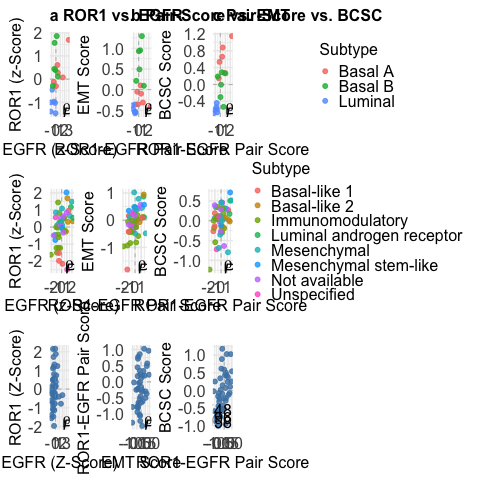

In [19]:
%%R
# ============================================
# FINALE FIGUR: 3x3-Grid, Nature-Style
# ============================================

row1 <- (p21 | p22 | p23) + plot_layout(guides = "collect") & theme(legend.position = "right")
row2 <- (p11 | p12 | p13) + plot_layout(guides = "collect") & theme(legend.position = "right")
row3 <- (p31 | p32 | p33)

final_figure <- row1 / row2 / row3 +
theme(plot.tag = element_text(size = 18, face = "bold"))

print(final_figure)

ggsave("output/ROR1_EGFR_combined_3x3.svg",
       plot = final_figure,
       width = 17,   # was 16
       height = 18,  # was 15
       dpi = 300)